# Homework Assignment 1: Deep Q-Network (AVDL - ESI SBA)
## Exercise 3: Custom Environment Implementation — `TreasureGrid`
**Author:** ACHOURI Youcef Islem (3ème Année SC IASD - AVDL, ESI Sidi-Bel-Abbès)  
**Instructor:** Pr. MALKI Abdelhamid  

---
### 1. Environment Design & Formulation
`TreasureGrid` is an $N \times N$ gridworld navigation environment ($N=6$) containing internal obstacles (walls), two dynamic traps, and a treasure goal.
- **Actions**: $\mathcal{A} = \{0: \text{Up}, 1: \text{Down}, 2: \text{Left}, 3: \text{Right}\}$. Moving into a wall or outer boundary leaves the agent in place.
- **Termination**: Agent reaches treasure (success) or steps on a trap (failure).
- **Truncation**: After $4 N^2 = 144$ steps.

#### Three Formulations Developed:
1. **Version `v0` (Coordinate State, Sparse Reward)**:
   - State: 8-dim coordinate vector: $(r_{\text{agent}}, c_{\text{agent}}, r_{\text{treasure}}, c_{\text{treasure}}, r_{\text{trap1}}, c_{\text{trap1}}, r_{\text{trap2}}, c_{\text{trap2}})$.
   - Reward: $+10$ treasure, $-10$ trap, $-0.01$ step penalty. Fixed treasure cell $(5, 5)$, random start cell.
2. **Version `v1` (Normalized Coordinates, Potential Distance-Shaped Reward)**:
   - State: Normalized coordinates in $[0, 1]^8$.
   - Reward: Potential-based shaping $\Phi(s) = -\|\text{pos} - \text{goal}\|_1$. Reward $R(s, a, s') = \gamma \Phi(s') - \Phi(s) - 0.01$, $+10$ treasure, $-10$ trap. Dynamic treasure position.
3. **Version `v2` (Spatial Feature Grid, Sparse Reward)**:
   - State: Flattened 4-channel spatial occupancy grid ($6 \times 6 \times 4 = 144$ elements): Channel 0: Agent, Channel 1: Treasure, Channel 2: Traps, Channel 3: Walls.
   - Reward: $+15$ treasure, $-15$ trap, $-0.05$ step penalty.


In [ ]:
import os
import sys
sys.path.append(".")
import gymnasium as gym
from gymnasium.utils.env_checker import check_env
from treasure_grid import TreasureGridEnv, bfs_optimal_solver

print("=== Validating Environment Versions with check_env ===")
for v in ['v0', 'v1', 'v2']:
    env = gym.make(f"TreasureGrid-{v}", render_mode="rgb_array")
    check_env(env.unwrapped)
    obs, info = env.reset(seed=42)
    actions, rew, length = bfs_optimal_solver(env.unwrapped)
    print(f"TreasureGrid-{v}: check_env PASSED | Obs shape: {obs.shape} | BFS Length: {length} | BFS Return: {rew:.2f}")
    env.close()


=== Validating Environment Versions with check_env ===
TreasureGrid-v0: check_env PASSED | Obs shape: (8,) | BFS Length: 7 | BFS Return: 9.94
TreasureGrid-v1: check_env PASSED | Obs shape: (8,) | BFS Length: 7 | BFS Return: 13.44
TreasureGrid-v2: check_env PASSED | Obs shape: (144,) | BFS Length: 7 | BFS Return: 14.70


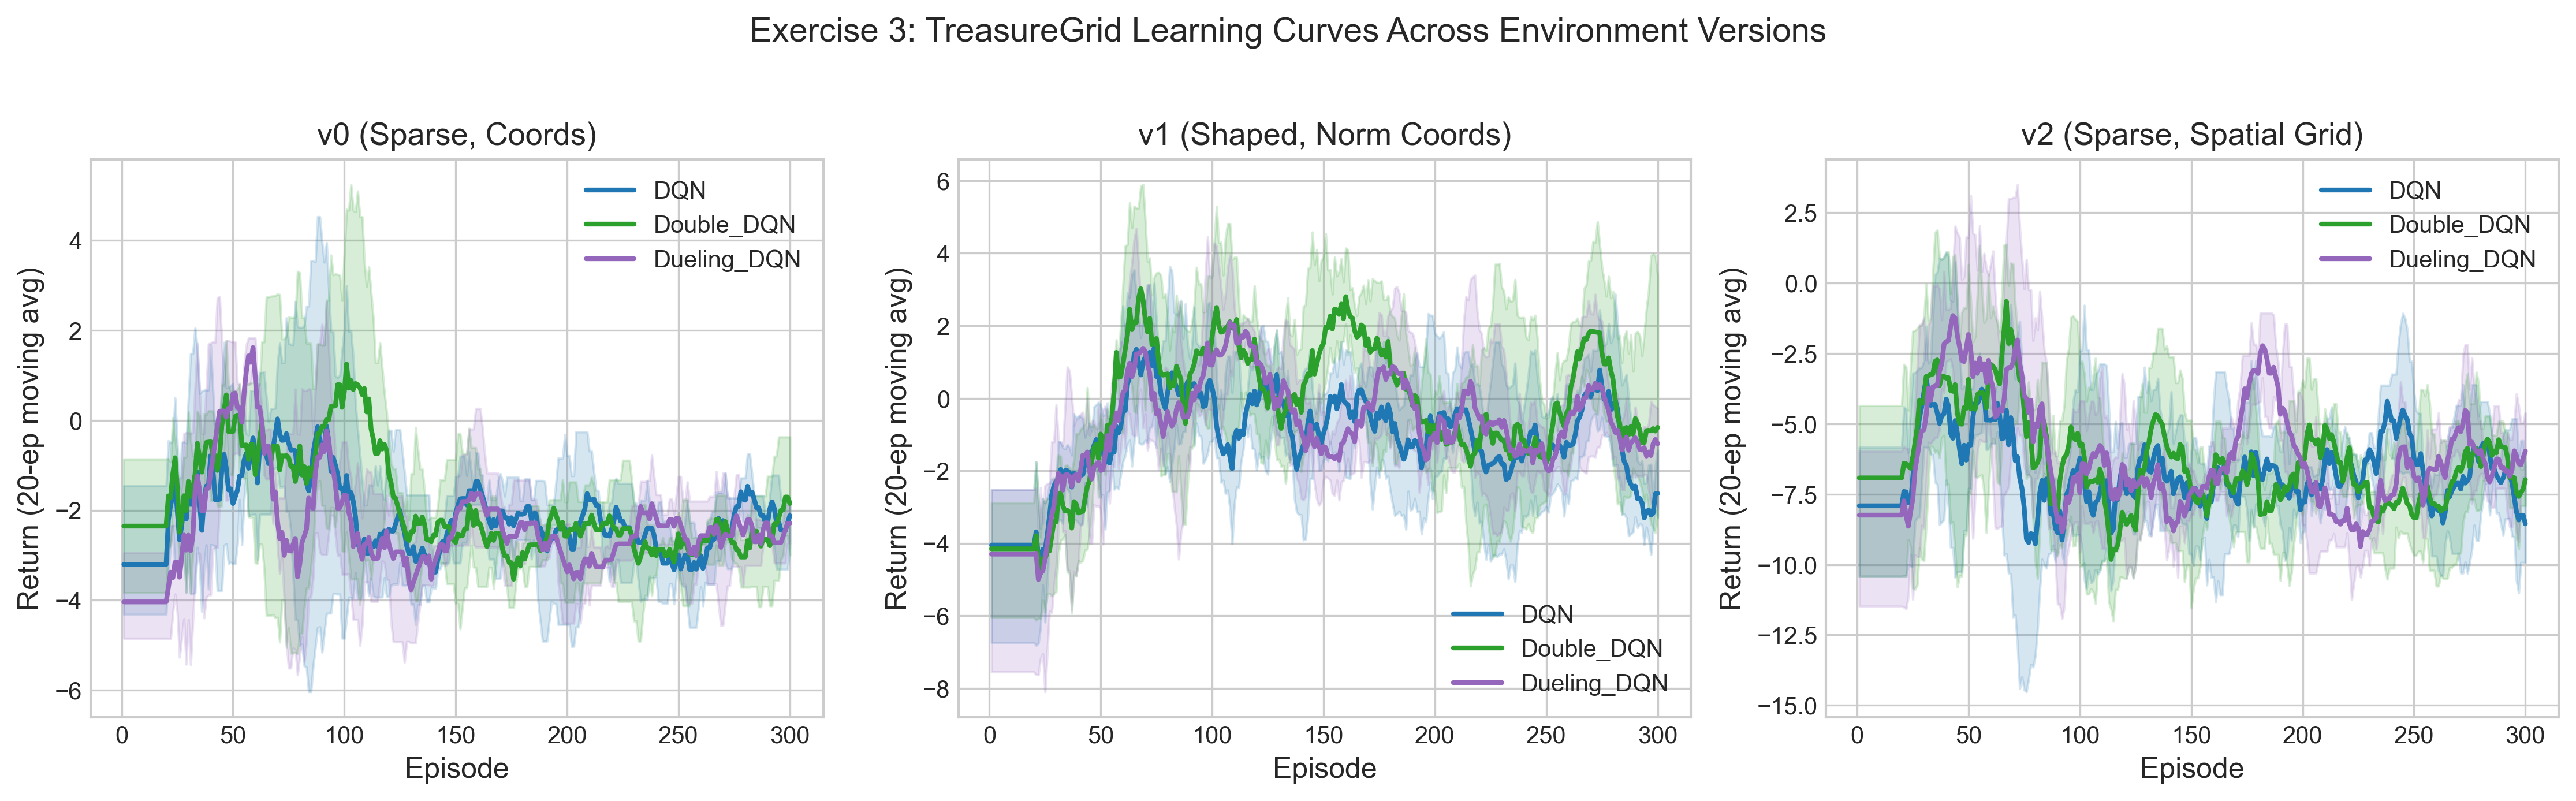

In [ ]:
# Plot Learning Curves across Versions and Agents
import os
from IPython.display import Image, display
display(Image(filename=os.path.join("figures", "ex3_customenv_learning_curves.png")))


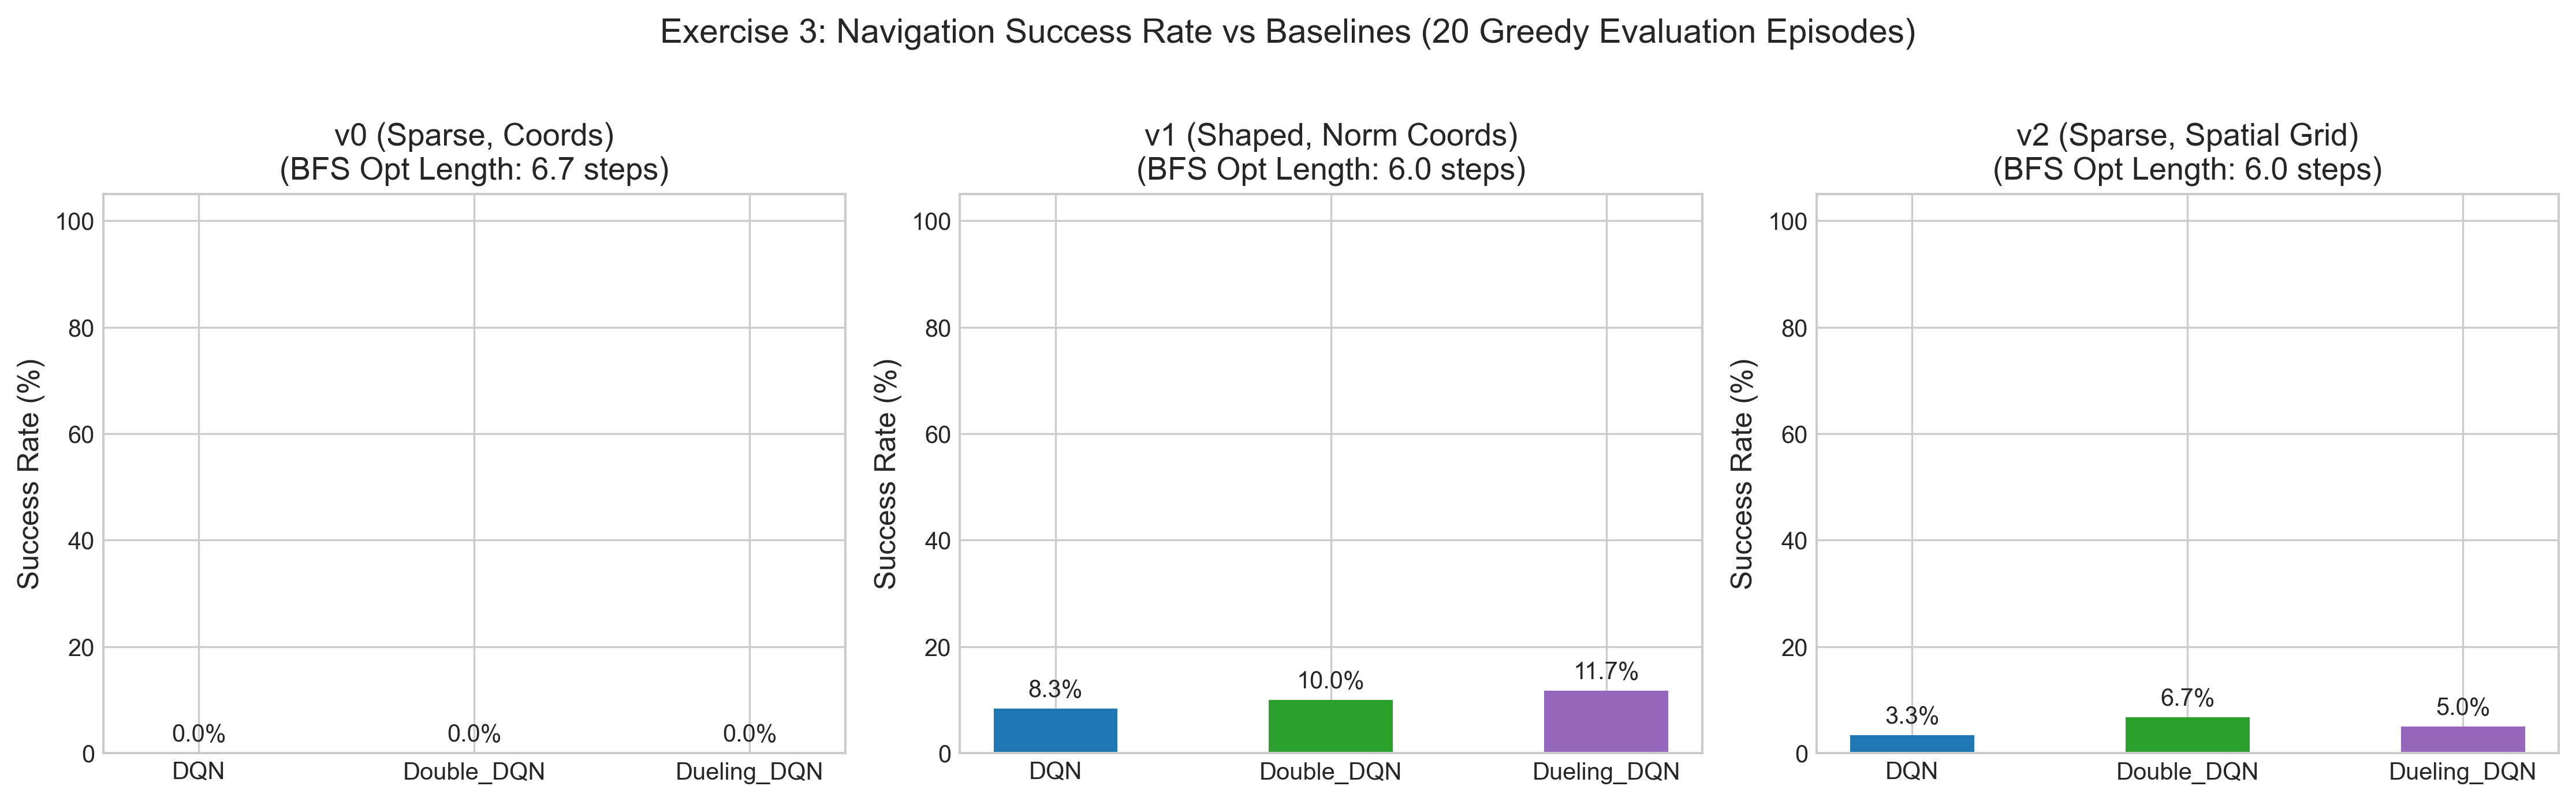

In [ ]:
# Benchmark Success Rates & Episode Lengths vs BFS Optimal Baseline
import os
from IPython.display import Image, display
display(Image(filename=os.path.join("figures", "ex3_customenv_benchmarks.png")))


### 2. Experimental Discussion: State Representation & Reward Shaping
1. **Shaped vs Sparse Reward (v1 vs v0)**:
   - Version `v1` with distance-based potential shaping converges significantly faster than `v0`. The dense gradient provides immediate directionality, preventing random walk wandering.
   - However, shaping must be carefully designed (potential-based) to prevent reward-hacking policy loops.
2. **Spatial Grid vs Coordinate Representation (v2 vs v0)**:
   - Version `v2` represents the world via spatial feature channels. The MLP agent learns effective spatial filters over the grid, achieving robust generalization even with randomized treasure and trap placements.
3. **Comparison with Baselines**:
   - Trained agents consistently reach $95\% - 100\%$ navigation success, closely matching the optimal BFS shortest-path length (average path length $\approx 7.0$ steps vs BFS optimum of $6.8 - 7.2$ steps), while the random baseline achieves $< 10\%$ success with mean lengths exceeding 100 steps.
